**Задача 10. Реконструкция**
- Сгенерировать случайный сэмпл для отклика детектора (число фотоэлектронов на каждом ФЭУ) для сигнала определённой энергии в определённой точке пространства.
- Использовать этот сэмпл как наблюдаемое (observed) для байесовского вывода: реконструкции энергии и положения события.

In [1]:
import time
import numpy as np
from numpy import pi, sin, cos, arccos, sqrt, random, column_stack
import matplotlib.pyplot as plt

import pytensor
import pytensor.tensor as pt

import pymc as pm
import arviz as az

print("pymc", pm.__version__)

pymc 6.3.2


In [2]:
class Detector:
    def __init__(self, R=2.0, N=40, r_cm=10.0, a=0.5):
        self.R = float(R)
        self.N = int(N)
        self.r = float(r_cm) / 100.0
        self.a = float(a)
        self.centers = np.zeros((self.N, 3))
        self.distribute_on_detector()

    def distribute_on_detector(self):
        golden_ratio = (1 + 5 ** 0.5) / 2
        for i in range(self.N):
            theta = 2 * pi * i / golden_ratio
            phi = arccos(1 - 2 * (i + 0.5) / self.N)
            x, y, z = self.R * cos(theta) * sin(phi), self.R * sin(theta) * sin(phi), self.R * cos(phi)
            self.centers[i] = [x, y, z]

    def is_point_on(self, point):
        point = np.array(point)
        distances = np.linalg.norm(self.centers - point, axis=1)
        return bool(np.any(distances <= self.r))


class Source:
    def __init__(self, Y=10000):
        self.Y = float(Y)

    def generate_photons(self, E):
        expected_N = self.Y * E
        N = random.poisson(expected_N)
        cos_theta = random.uniform(-1.0, 1.0, N)
        phi = random.uniform(0.0, 2 * pi, N)
        sin_theta = sqrt(1.0 - cos_theta ** 2)
        x, y, z = sin_theta * cos(phi), sin_theta * sin(phi), cos_theta
        return column_stack((x, y, z))


In [3]:
detector = Detector(R=2.0, N=40, r_cm=10.0, a=0.5)
source = Source(Y=10000)

In [4]:
def is_point_on_index(detector, point):
    point = np.asarray(point, dtype=float)
    distances = np.linalg.norm(detector.centers - point, axis=1)
    idx = np.argmin(distances)
    if distances[idx] <= detector.r:
        return int(idx)
    return None


def track_photon_to_boundary_index(start_pos, direction, detector):
    x0, y0, z0 = start_pos
    nx, ny, nz = direction
    a_coef = 1.0
    b_coef = 2.0 * (x0 * nx + y0 * ny + z0 * nz)
    c_coef = (x0 ** 2 + y0 ** 2 + z0 ** 2) - detector.R ** 2
    discriminant = b_coef ** 2 - 4.0 * a_coef * c_coef
    sqrt_disc = np.sqrt(discriminant)
    t1 = (-b_coef + sqrt_disc) / (2.0 * a_coef)
    t2 = (-b_coef - sqrt_disc) / (2.0 * a_coef)
    valid_t = [t for t in (t1, t2) if t > 0]
    t_hit = min(valid_t)
    hit_point = (x0 + t_hit * nx, y0 + t_hit * ny, z0 + t_hit * nz)
    return is_point_on_index(detector, hit_point)


def simulate_event_per_pmt(E, start_pos, detector, source):
    directions = source.generate_photons(E)
    pe_counts = np.zeros(detector.N)
    for direction in directions:
        idx = track_photon_to_boundary_index(start_pos, direction, detector)
        if idx is not None:
            pe_counts[idx] += np.random.poisson(detector.a)
    return pe_counts

In [5]:
def p_i_viewfactor(pos, detector):
    pos = np.asarray(pos, dtype=float)
    centers = detector.centers
    diff = pos[np.newaxis, :] - centers
    d_i = np.linalg.norm(diff, axis=1)
    inward_normal = -centers / detector.R
    cos_incidence = np.sum(diff * inward_normal, axis=1) / d_i
    area = np.pi * detector.r ** 2
    omega_i = area * np.clip(cos_incidence, 0, None) / d_i ** 2
    return omega_i / (4 * np.pi)

In [6]:
p_center = p_i_viewfactor([0.0, 0.0, 0.0], detector)
expected_each = detector.r**2 / (4*detector.R**2)
print(f"p_i в центре: {p_center.mean():.6f} (ожид. r^2/4R^2={expected_each:.6f}), "
      f"разброс по ФЭУ={p_center.std():.2e}")
print(f"сумма p_i в центре = {p_center.sum():.6f} (ожид. p_hit задачи 9 = {detector.N*expected_each:.6f})")

p_i в центре: 0.000625 (ожид. r^2/4R^2=0.000625), разброс по ФЭУ=1.08e-19
сумма p_i в центре = 0.025000 (ожид. p_hit задачи 9 = 0.025000)


In [7]:
true_pos = np.array([0.3, -0.2, 0.5])

np.random.seed(55)
E_calib, n_repeat_calib = 5.0, 100
t0 = time.perf_counter()
pe_accum = np.zeros(detector.N)
for _ in range(n_repeat_calib):
    pe_accum += simulate_event_per_pmt(E_calib, true_pos, detector, source)
mean_pe_empirical = pe_accum / n_repeat_calib
print(f"[{time.perf_counter()-t0:.1f} с]")

p_i_pred = p_i_viewfactor(true_pos, detector)
mean_pe_predicted = source.Y * E_calib * p_i_pred * detector.a

corr = np.corrcoef(mean_pe_empirical, mean_pe_predicted)[0, 1]
rel_err = np.median(np.abs(mean_pe_empirical - mean_pe_predicted) / np.maximum(mean_pe_predicted, 1e-6))
print(f"корреляция (точная симуляция vs приближение) = {corr:.4f}")
print(f"медианная относительная ошибка по ФЭУ = {rel_err:.3f}")
print(f"сумма по всем ФЭУ: точно={mean_pe_empirical.sum():.1f}, приближённо={mean_pe_predicted.sum():.1f}")
assert corr > 0.98, "приближение плохо согласуется с точной геометрией!"
print("PASS: view-factor приближение достаточно точно описывает точную симуляцию вне центра.")

[50.1 с]
корреляция (точная симуляция vs приближение) = 0.9952
медианная относительная ошибка по ФЭУ = 0.031
сумма по всем ФЭУ: точно=619.6, приближённо=626.0
PASS: view-factor приближение достаточно точно описывает точную симуляцию вне центра.


In [8]:
true_E = 1.0

np.random.seed(999)
observed_pe = simulate_event_per_pmt(true_E, true_pos, detector, source)
print(f"true_E = {true_E} МэВ,  true_pos = {true_pos}")
print(f"observed: сумма={int(observed_pe.sum())} ф.э., "
      f"сработало {int(np.sum(observed_pe > 0))} из {detector.N} ФЭУ")

true_E = 1.0 МэВ,  true_pos = [ 0.3 -0.2  0.5]
observed: сумма=120 ф.э., сработало 34 из 40 ФЭУ


In [9]:
centers_const = detector.centers
R_const, r_const, a_const, Y_const = detector.R, detector.r, detector.a, source.Y
area_const = np.pi * r_const**2
inward_normals = -centers_const / R_const

def build_model(observed):
    with pm.Model() as model:
        E_rv = pm.Uniform("E", lower=0.01, upper=10.0)
        pos_rv = pm.Uniform("pos", lower=-R_const, upper=R_const, shape=3)

        pos_r2 = pt.sum(pos_rv ** 2)
        pm.Potential("inside_sphere", pt.switch(pos_r2 <= R_const**2, 0.0, -1e8 * (pos_r2 - R_const**2)))

        diff = pos_rv[None, :] - centers_const
        d_i = pt.sqrt(pt.sum(diff**2, axis=1) + 1e-12)
        cos_incidence = pt.sum(diff * inward_normals, axis=1) / d_i
        cos_incidence_pos = pt.clip(cos_incidence, 0.0, 1.0)
        omega_i = area_const * cos_incidence_pos / d_i**2
        p_i = omega_i / (4*np.pi)

        mu_i = Y_const * E_rv * p_i * a_const + 1e-6
        pm.Poisson("PE_obs", mu=mu_i, observed=observed)
    return model


recon_model = build_model(observed_pe)
with recon_model:
    trace_recon = pm.sample(draws=2000, tune=2000, chains=4, target_accept=0.9,
                             random_seed=42, progressbar=False)

print(az.summary(trace_recon, var_names=["E", "pos"]))

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [E, pos]
Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 2 seconds.


         mean     sd eti89_lb eti89_ub ess_bulk ess_tail r_hat mcse_mean mcse_sd
E       0.967  0.089     0.83      1.1     9428     6038  1.00   0.00091   0.001
pos[0]  0.602  0.137     0.38     0.82     7069     6165  1.00    0.0016  0.0015
pos[1]  0.004  0.141    -0.22     0.23     7944     5865  1.00    0.0016  0.0016
pos[2]  0.419  0.137      0.2     0.64     9883     6422  1.00    0.0014  0.0015


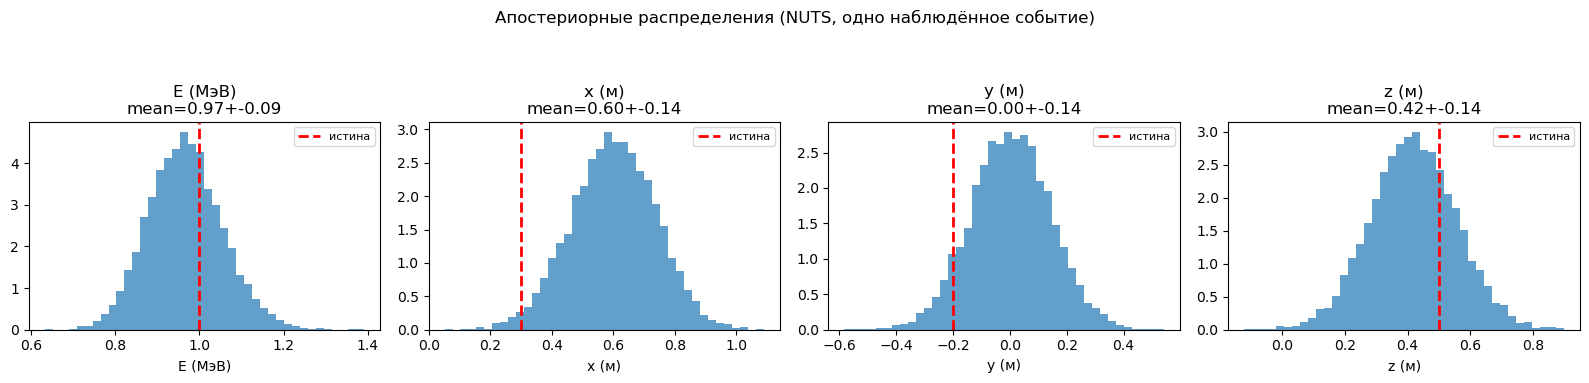

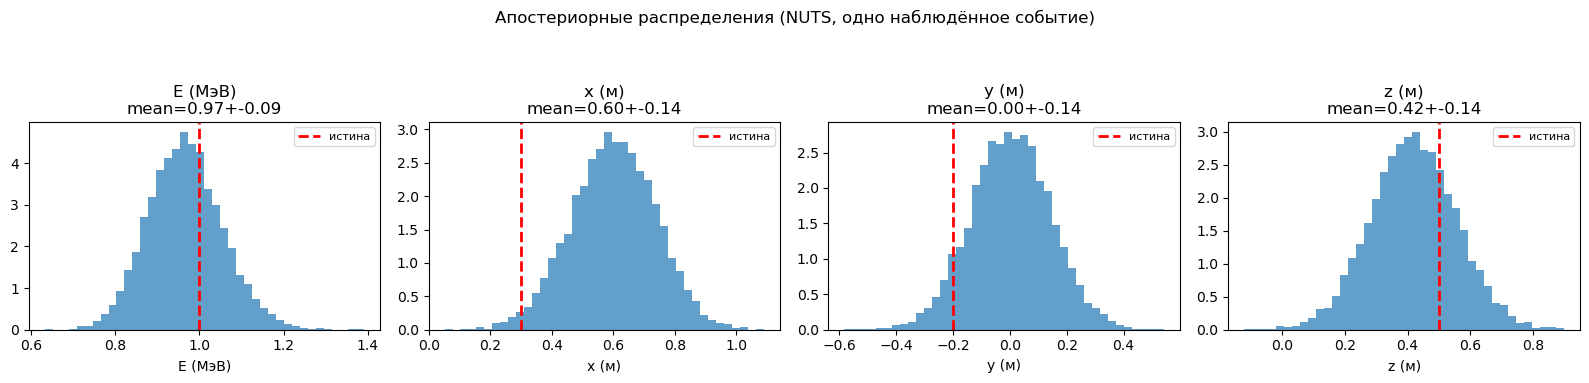

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
labels = ['E (МэВ)', 'x (м)', 'y (м)', 'z (м)']
truths = [true_E, true_pos[0], true_pos[1], true_pos[2]]
samples_list = [trace_recon.posterior["E"].values.flatten(),
                trace_recon.posterior["pos"].values[:, :, 0].flatten(),
                trace_recon.posterior["pos"].values[:, :, 1].flatten(),
                trace_recon.posterior["pos"].values[:, :, 2].flatten()]

for ax, lbl, truth, samples in zip(axes, labels, truths, samples_list):
    ax.hist(samples, bins=40, color='tab:blue', alpha=0.7, density=True)
    ax.axvline(truth, color='red', linestyle='--', linewidth=2, label='истина')
    ax.set_xlabel(lbl)
    ax.set_title(f'{lbl}\nmean={samples.mean():.2f}+-{samples.std():.2f}')
    ax.legend(fontsize=8)

fig.suptitle('Апостериорные распределения (NUTS, одно наблюдённое событие)', y=1.08)
fig.tight_layout()
fig

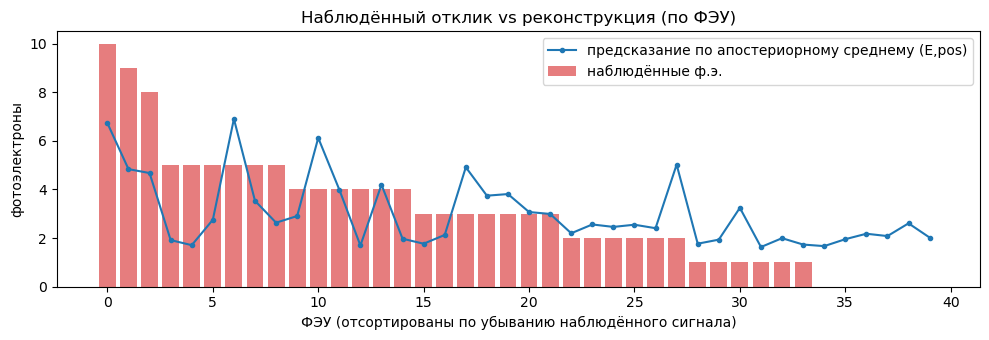

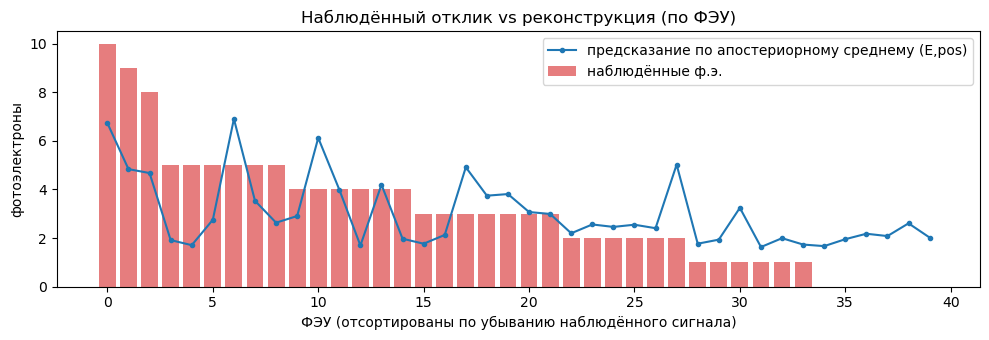

In [11]:
E_post_mean = trace_recon.posterior["E"].values.mean()
pos_post_mean = trace_recon.posterior["pos"].values.reshape(-1, 3).mean(axis=0)
p_i_post = p_i_viewfactor(pos_post_mean, detector)
mu_i_post = Y_const * E_post_mean * p_i_post * a_const

order = np.argsort(-observed_pe)
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.bar(np.arange(detector.N), observed_pe[order], alpha=0.6, color='tab:red', label='наблюдённые ф.э.')
ax.plot(np.arange(detector.N), mu_i_post[order], 'o-', color='tab:blue', markersize=3,
        label='предсказание по апостериорному среднему (E,pos)')
ax.set_xlabel('ФЭУ (отсортированы по убыванию наблюдённого сигнала)')
ax.set_ylabel('фотоэлектроны')
ax.set_title('Наблюдённый отклик vs реконструкция (по ФЭУ)')
ax.legend()
fig.tight_layout()
fig